# Penny et al. (2023): sympathetic cooling of two Coulomb-coupled nanoparticles

T. W. Penny, A. Pontin and P. F. Barker, *Sympathetic cooling and squeezing of two colevitated
nanoparticles*, Phys. Rev. Research **5**, 013070 (2023),
[doi:10.1103/physrevresearch.5.013070](https://doi.org/10.1103/physrevresearch.5.013070)
(open version: arXiv:2111.03123v3).

Two charged silica spheres share the axial potential of a linear Paul trap and repel each other.
Their axial motions form two normal modes, whose shapes depend on the two charges. Feedback
damping applied to particle 1 alone cools both modes, and through them particle 2. This notebook
describes the trap with levisim's `PaulTrap` force element (a linear Paul trap with the paper's
electrode coefficients) and the repulsion with its direct interactions
(`levisim.physics.interactions.Coulomb`), to

1. compute the normal modes from the measured charges and separation, and compare the mode
   shapes $r_\pm$ and the energy fractions with the paper's values (Sec. IV),
2. check that a `MultiTrap` of two traps holding the `PaulTrap` and coupled by `Coulomb`
   reproduces the same normal-mode frequencies,
3. check the full radio-frequency force of the `PaulTrap` in the time domain against its secular
   (pseudopotential) description, then simulate both particles (`MultiParticleFreeSpaceSimulation`)
   in thermal equilibrium and with cold damping on particle 1, and compare the mode temperatures
   with the exact linear (Lyapunov) prediction,
4. estimate the detection-noise-limited temperature of the paper's Eq. (22) at its stated
   pressure and imprecision noise, against the measured 200 mK.

Runtime: about half a minute (the time-domain runs use the numba kernel when it is installed).

## Parameters and where they come from

| Quantity | Value used | Source |
|---|---|---|
| charges | $Q_1$ = 2135 e, $Q_2$ = 906 e | Sec. IV (from the radial frequencies) |
| radii, density | 193.5 nm nominal (measured 195 ± 3 and 192 ± 3 nm), 1850 kg/m³ | Sec. IV |
| equilibrium separation | $z^\mathrm{eq}_\mathrm{sep}$ = 198 ± 1 μm | Sec. IV, Fig. 1b |
| trap coefficients | $r_0$ = 1.1 mm, $z_0$ = 3.5 mm, $\kappa$ = 0.071, $\eta$ = 0.82 | Sec. III (finite-element model) |
| rf drive | $V_0$ = 150 V, $\omega_\mathrm{rf}$ = 2π × 10 kHz (assumed) | Sec. III gives the typical ranges 100-150 V and 2π × (8-12) kHz only |
| bath temperature | 293 K | Sec. V |
| pressures | 1.3 × 10⁻² mbar (thermal equilibrium), 3.2 × 10⁻⁷ mbar (cooling) | Fig. 2, Sec. V |
| imprecision noise | $S_{nn}$ = 3 × 10⁻¹⁵ m²/Hz | Sec. V |

The trap is `PaulTrap.linear`: rf on the rods (curvatures $(1, -1, 0)$ at $r_0$, efficiency
$\kappa_\mathrm{geom} = \eta$) and the dc endcaps along $z$ (curvatures $(-\tfrac12, -\tfrac12, 1)$ at
$z_0$). The paper's axial stiffness is $u_i = 2Q_i\kappa U_0/z_0^2$; levisim's linear preset writes the
endcap potential as $\kappa_\mathrm{endcap}U_\mathrm{endcap}(z^2 - (x^2 + y^2)/2)/(2z_0^2)$, with axial
stiffness $Q\kappa_\mathrm{endcap}U_\mathrm{endcap}/z_0^2$, so the paper's convention is
$\kappa_\mathrm{endcap} = 2\kappa$. The endcap voltage $U_0$ of this measurement is not given; the force
balance $u_1|z_1| = u_2 z_2 = Q_1Q_2/(4\pi\varepsilon_0 d^2)$ fixes it from the charges and the
separation alone, $2\kappa U_0/z_0^2 = (Q_1 + Q_2)/(4\pi\varepsilon_0 d^3)$. The rf voltage and frequency
set only the radial secular frequencies, which do not enter any compared number (with these charges
the radial modes do not couple to the axial ones); the paper does not state the radial potential, so
using $\eta$ as levisim's rf efficiency $\kappa_\mathrm{geom}$ is an assumption.

Axes: the Paul-trap axis is levisim's $z$. levisim uses angular-frequency units throughout
(`levisim.core.units.Hz` = 2π).

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve_continuous_lyapunov
from scipy.optimize import curve_fit
from scipy.signal import butter, sosfiltfilt, welch

from levisim.core.constants import e, kB, π, ε0
from levisim.core.units import Hz, kHz, mm, μm, nm, mbar, μs
from levisim.core.plotting import set_plt_rcParams_to_xmgrace_style
from levisim.physics.bead import Bead
from levisim.physics.fields import PaulTrap
from levisim.physics.gas import Gas
from levisim.physics.trap import Trap
from levisim.physics.tweezer import Tweezer
from levisim.physics.interactions import Coulomb
from levisim.multiphysics.multitrap import MultiTrap
from levisim.simulation import MultiParticleFreeSpaceSimulation

set_plt_rcParams_to_xmgrace_style()
T_START = time.time()

Q1, Q2 = 2135, 906          # [e]
d = 198 * μm                # equilibrium separation
T0 = 293.0                  # [K]
κ_paper, η_paper = 0.071, 0.82
r0_paper, z0_paper = 1.1 * mm, 3.5 * mm
V0, Ω_rf = 150.0, 10 * kHz  # assumed, within the paper's typical ranges
U0 = (Q1 + Q2) * e / (4 * π * ε0 * d**3) * z0_paper**2 / (2 * κ_paper)  # from the force balance


def linear_paul_trap(centre=(0.0, 0.0, 0.0)):
    # the paper's linear Paul trap; its axial stiffness 2QκU0/z0² is levisim's Qκ_endcap·U/z0²
    # with κ_endcap = 2κ. `centre` is in the frame of the Trap that holds it
    return PaulTrap.linear(V_rf=V0, Ω_rf=Ω_rf, r0=r0_paper, U_endcap=U0, z0=z0_paper,
                           κ_geom=η_paper, κ_endcap=2 * κ_paper, centre=centre)


paul = linear_paul_trap()
print(f'endcap voltage from the separation: U0 = {U0:.1f} V (paper: typically 20-50 V)')

endcap voltage from the separation: U0 = 48.7 V (paper: typically 20-50 V)


## 1. Normal modes from the trap and Coulomb stiffness blocks

The particles sit at $z_1 = -dQ_2/(Q_1+Q_2)$ and $z_2 = dQ_1/(Q_1+Q_2)$ from the trap centre, where
the `PaulTrap`'s time-averaged force balances the repulsion. Its secular stiffness
(`PaulTrap.stiffness`) gives $u_i$, and `Coulomb().stiffness_blocks` the 3 × 3 blocks
$K_{jk} = -\partial F_j/\partial r_k$ at those positions; the axial dynamical matrix is
$V = M^{-1}(\mathrm{diag}(u) + K_{zz})$ (the paper's Eq. (5)), with eigenvectors
$e_\pm \propto (1, r_\pm)$ (Eq. (11)), $\omega_+ < \omega_-$.

In [2]:
def normal_modes(radii):
    beads = [Bead(r=radii[0], charge=Q1), Bead(r=radii[1], charge=Q2)]
    masses = np.array([bead.m for bead in beads])
    u = np.array([paul.stiffness(particle=bead)[2, 2] for bead in beads])
    z_eq = np.array([-d * Q2 / (Q1 + Q2), d * Q1 / (Q1 + Q2)])
    positions = np.array([[0, 0, z_eq[0]], [0, 0, z_eq[1]]])
    F_coulomb = Coulomb().forces(positions, beads)
    F_trap = np.array([paul.secular_force(position, bead) for position, bead in zip(positions, beads)])
    assert np.allclose(F_coulomb + F_trap, 0, atol=1e-12 * np.abs(F_coulomb).max())  # force balance
    K = Coulomb().stiffness_blocks(positions, beads)
    V = (np.diag(u) + K[:, :, 2, 2]) / masses[:, None]
    ω2, vectors = np.linalg.eig(V)
    order = np.argsort(ω2)
    ω2, vectors = ω2[order], vectors[:, order]
    return dict(beads=beads, masses=masses, u=u, z_eq=z_eq, K=K, ω2=ω2, vectors=vectors,
                r=vectors[1] / vectors[0], positions=positions)

nominal = normal_modes([193.5 * nm, 193.5 * nm])
measured = normal_modes([195 * nm, 192 * nm])
m = nominal['masses'][0]
f_bare = np.sqrt(nominal['u'] / nominal['masses']) / (2 * π)
print(f'mass {m:.4g} kg; uncoupled axial frequencies {f_bare[0]:.1f} Hz (particle 1), {f_bare[1]:.1f} Hz (particle 2)')
for n, bead in enumerate(nominal['beads']):
    a, q = paul.mathieu_parameters(bead)
    f_lowest = paul.secular_frequencies(bead, 'lowest') / Hz
    f_exact = paul.secular_frequencies(bead, 'exact') / Hz
    print(f'particle {n + 1}: radial a = {a[0]:+.2e}, |q| = {abs(q[0]):.3f}, stable {paul.is_stable(bead)}; '
          f'radial secular frequency {f_lowest[0]:.1f} Hz (pseudopotential), {f_exact[0]:.1f} Hz (Floquet)')
for name, modes in (('nominal radii', nominal), ('measured radii', measured)):
    f = np.sqrt(modes['ω2']) / (2 * π)
    r_plus, r_minus = modes['r']
    print(f'{name:15s}: f+ = {f[0]:.1f} Hz, f- = {f[1]:.1f} Hz, r+ = {r_plus:+.3f}, r- = {r_minus:+.3f},'
          f' r+·r- = {r_plus*r_minus:+.4f} (= -m1/m2 = {-modes["masses"][0]/modes["masses"][1]:+.4f})')
r_plus, r_minus = nominal['r']
fraction_1_plus = 1 / (1 + r_plus**2)
print(f'\nenergy fractions (Eqs. 18-19, equal masses): E1,+/E1 = E2,-/E2 = {fraction_1_plus:.3f},'
      f'  E2,+/E2 = E1,-/E1 = {1 - fraction_1_plus:.3f}')
print('paper (Sec. IV, from the same charges): r- = -1.60 ± 0.03, r+ = 0.61 ± 0.04, E1,+/E1 = E2,-/E2 = 0.72 ± 0.03')

mass 5.614e-17 kg; uncoupled axial frequencies 295.1 Hz (particle 1), 192.2 Hz (particle 2)
particle 1: radial a = -1.74e-03, |q| = 0.314, stable True; radial secular frequency 1089.5 Hz (pseudopotential), 1111.4 Hz (Floquet)
particle 2: radial a = -7.39e-04, |q| = 0.133, stable True; radial secular frequency 450.7 Hz (pseudopotential), 452.2 Hz (Floquet)
nominal radii  : f+ = 237.2 Hz, f- = 414.1 Hz, r+ = +1.594, r- = -0.628, r+·r- = -1.0000 (= -m1/m2 = -1.0000)
measured radii : f+ = 238.4 Hz, f- = 412.1 Hz, r+ = +1.557, r- = -0.673, r+·r- = -1.0476 (= -m1/m2 = -1.0476)

energy fractions (Eqs. 18-19, equal masses): E1,+/E1 = E2,-/E2 = 0.283,  E2,+/E2 = E1,-/E1 = 0.717
paper (Sec. IV, from the same charges): r- = -1.60 ± 0.03, r+ = 0.61 ± 0.04, E1,+/E1 = E2,-/E2 = 0.72 ± 0.03


levisim's in-phase mode has $r_+ = s_2/s_1 = +1.594$ and the out-of-phase mode $r_- = -0.628$
for particle 1 being the one with $Q_1$ = 2135 e. The paper's Eq. (12) with $Q_1$ = 2135 e gives
the same numbers. The values the paper quotes, $r_+$ = 0.61 and $r_-$ = −1.60, are their
reciprocals: they describe the same mode shapes with the particle labels exchanged (the more
weakly charged particle as "1"), and so does its energy fraction 0.72, which here is
$E_{2,+}/E_2 = E_{1,-}/E_1$ = 0.718. With that relabelling all three agree within the paper's
uncertainties (0.628 against 0.61 ± 0.04, −1.594 against −1.60 ± 0.03, 0.718 against 0.72 ± 0.03).
With the measured radii, $r_+ r_- = -m_1/m_2$ moves from −1 to −1.048, which shifts $r_\pm$ by up to
7 %; the paper's comparison assumes equal masses.

## 2. The same modes in `MultiTrap`

Each particle gets its own trap, placed at its equilibrium position (`trap_positions`) and holding
the same `PaulTrap` with its centre at the common trap centre (`centre` is in the trap's own frame,
so it is $-z^\mathrm{eq}_i$). `MultiTrap` always builds a tweezer per trap; `Tweezer(Power=0)`
switches it off, and no cavity coupling remains. With `interactions=[Coulomb()]`, `MultiTrap` adds
each particle's own Coulomb block to its frequency, $\Omega_j^2 = \Omega_{j,\mathrm{trap}}^2 + K_{jj}/m$,
and turns the cross blocks into the coupling rates of $H/\hbar \ni -g_{jk}q_jq_k$
($q = b + b^\dagger$, $x = x_\mathrm{zpf}q$), $g_{jk} = -K_{jk}x_{\mathrm{zpf},j}x_{\mathrm{zpf},k}/\hbar$.
The axial ($z$) rows of its drift matrix decouple from the radial ones, and their eigenfrequencies
are the normal modes above.

In [3]:
gas_thermal = Gas(P=1.3e-2 * mbar, T=T0)
mtrap = MultiTrap(
    num_traps=2, Cartesian_axes_per_trap=3, ω_range=np.linspace(100, 1500, 1401) * Hz,
    beads=nominal['beads'], tweezers=[Tweezer(Power=0.0), Tweezer(Power=0.0)],
    trap_positions=[tuple(position) for position in nominal['positions']],
    trap_kwargs=[{'extra_fields': [linear_paul_trap(centre=-position)]} for position in nominal['positions']],
    interactions=[Coulomb()], gas_kwargs={'P': gas_thermal.P, 'T': T0},
    photon_recoil=False, static_cavity_shifts=False,
)
labels = list(mtrap.dimensions)
rows = lambda names: [2 + 2 * labels.index(name) + k for name in names for k in (0, 1)]
λ_axial = np.linalg.eigvals(mtrap.drift_matrix[np.ix_(rows(['z1', 'z2']), rows(['z1', 'z2']))])
f_drift = np.sort(np.abs(λ_axial.imag))[::2] / (2 * π)
λ_radial = np.linalg.eigvals(mtrap.drift_matrix[np.ix_(rows(['x1', 'x2']), rows(['x1', 'x2']))])
f_radial = np.sort(np.abs(λ_radial.imag))[::2] / (2 * π)
f_modes = np.sqrt(nominal['ω2']) / (2 * π)
Ω_dims = {label: mtrap.dimensions[label].Ω / Hz for label in ('z1', 'z2')}
print(f"shifted axial frequencies Ω/2π = {Ω_dims['z1']:.2f}, {Ω_dims['z2']:.2f} Hz")
print(f'axial drift-matrix eigenfrequencies {f_drift[0]:.6f}, {f_drift[1]:.6f} Hz; normal modes {f_modes[0]:.6f}, {f_modes[1]:.6f} Hz')
print(f'relative difference {np.max(np.abs(f_drift / f_modes - 1)):.1e}')
print(f'radial (x) normal modes, pseudopotential and Coulomb: {f_radial[0]:.2f}, {f_radial[1]:.2f} Hz')

shifted axial frequencies Ω/2π = 372.74, 298.03 Hz
axial drift-matrix eigenfrequencies 237.207047, 414.110401 Hz; normal modes 237.207047, 414.110401 Hz
relative difference 4.4e-16
radial (x) normal modes, pseudopotential and Coulomb: 420.12, 1077.85 Hz


The coupling here is ultrastrong ($g/\Omega \approx$ 0.5, the modes are 40 % apart), and
`MultiTrap`'s thermal bath acts on both quadratures of each local oscillator at its own frequency
(levisim's quantum Langevin model). That bath does not bring strongly coupled normal modes to a
common temperature, so the thermal *spectra* of this system are not the classical Brownian
ones. Thermal properties are therefore taken from the time-domain simulation below, whose bath
is the classical Brownian force on each momentum.

## 3. Time domain: the rf force, thermal equilibrium and sympathetic cooling

**The rf force against its secular description.** `MultiParticleFreeSpaceSimulation` integrates the
`PaulTrap`'s full time-dependent force when a trap holds it. That needs a step that resolves the
10 kHz drive (40 steps per rf period here) and runs the NumPy loop, about 0.2 ms per step for the
pair, so it is used for a short noise-free check (gas at 10⁻¹² mbar): both particles start
displaced, once in traps holding the `PaulTrap` and once in traps whose harmonic potentials have the
`PaulTrap`'s secular frequencies (`PaulTrap.secular_frequencies`, the pseudopotential, set through
`override_Ω_dict`). The axial motion has no rf curvature in a linear trap and must agree; the radial
secular frequencies of the rf run must be the coupled pseudopotential modes of Sec. 2 plus each
particle's exact (Floquet) correction, `secular_frequencies(..., 'exact', extra_stiffness=K_nn)`.

**Thermal runs.** The 40 s records below (2 × 10⁶ steps of 20 μs per gain) would take about half an
hour each with the rf resolved, so they use the secular traps, on the numba kernel. Both traps are
centred at the origin (one Paul trap) and the particles start at their equilibrium positions. Gas
damping $\gamma_0$ and its thermal force noise come from levisim's `Gas` at 1.3 × 10⁻² mbar (where the
paper measured thermal equilibrium); levisim's optional directed noise is switched off ($\beta$ = 0).
Cold damping $\gamma_\mathrm{fb}$ (a `Feedback` element without added noise) acts on particle 1's
axial motion only. The normal-mode temperatures are $T_k = M_k\omega_k^2\langle A_k^2\rangle/k_B$, with
$A_k$ the mode amplitudes ($s = \sum_k A_k e_k$) and $M_k = \sum_i m_i e_{ki}^2$.

The exact prediction is the stationary covariance of the same linear equations,
$\dot{u} = Au + \xi$ with $u = (s_1, s_2, v_1, v_2)$: $AV + VA^T + D = 0$, with
$D = \mathrm{diag}(0, 0, 2\gamma_0k_BT_0/m_1, 2\gamma_0k_BT_0/m_2)$.

In [4]:
K = nominal['K']
gas_vacuum = Gas(P=1e-12 * mbar, T=T0)


def secular_override(bead):
    # the PaulTrap's secular (pseudopotential) frequencies about its centre, for the harmonic traps
    return dict(zip('xyz', paul.secular_frequencies(bead, 'lowest')))


def rf_check_run(rf):
    traps = [Trap(fields=[paul], bead=bead, gas=gas_vacuum, β=0.0) if rf else
             Trap(bead=bead, override_Ω_dict=secular_override(bead), Γ_fbx=0, Γ_fby=0, Γ_fbz=0, gas=gas_vacuum, β=0.0)
             for bead in nominal['beads']]
    X0 = np.zeros(12)
    X0[2], X0[8] = nominal['z_eq']
    X0[2] += 2 * μm   # axial
    X0[0] += 1 * μm   # radial, particle 1
    X0[6] += 1 * μm   # radial, particle 2
    return MultiParticleFreeSpaceSimulation(traps=traps, interactions=[Coulomb()], X0=X0, num_samples=20_000,
                                            Δt=2.5 * μs, seed=3, zero_mean=False, backend='numpy')


def fitted_frequency(x, Δt, f_guess):
    y = sosfiltfilt(butter(4, 3 * f_guess, fs=1 / Δt, output='sos'), x)  # removes the micromotion
    t = np.arange(len(y)) * Δt
    model = lambda t, A, f, φ, c: A * np.cos(2 * π * f * t + φ) + c
    p, _ = curve_fit(model, t, y, p0=[np.ptp(y) / 2, f_guess, 0, 0])
    return p[1]


rf_run, secular_run = rf_check_run(True), rf_check_run(False)
for label in ('z1', 'z2'):
    a, b = rf_run.traces[label].values, secular_run.traces[label].values
    print(f'{label}: largest difference rf - secular {np.max(np.abs(a - b)) / np.ptp(b):.1e} of the peak-to-peak axial motion')
for n, label in enumerate(('x1', 'x2')):
    bead = nominal['beads'][n]
    correction = (paul.secular_frequencies(bead, 'exact', extra_stiffness=K[n, n])
                  - paul.secular_frequencies(bead, 'lowest', extra_stiffness=K[n, n]))[0] / (2 * π)
    expected = f_radial[::-1][n] + correction
    fitted = fitted_frequency(rf_run.traces[label].values, rf_run.Δt, expected)
    print(f'{label}: rf run {fitted:.2f} Hz; pseudopotential mode {f_radial[::-1][n]:.2f} Hz + Floquet correction '
          f'{correction:.2f} Hz = {expected:.2f} Hz')

z1: largest difference rf - secular 5.6e-04 of the peak-to-peak axial motion
z2: largest difference rf - secular 7.2e-04 of the peak-to-peak axial motion
x1: rf run 1099.34 Hz; pseudopotential mode 1077.85 Hz + Floquet correction 21.50 Hz = 1099.35 Hz
x2: rf run 421.48 Hz; pseudopotential mode 420.12 Hz + Floquet correction 1.37 Hz = 421.49 Hz


In [5]:
vectors, ω2, masses = nominal['vectors'], nominal['ω2'], nominal['masses']
mode_masses = np.array([np.sum(masses * vectors[:, k]**2) for k in range(2)])


def axial_trap(bead, Γ_fbz):
    # a harmonic trap with the PaulTrap's secular frequencies (see the rf check above)
    return Trap(bead=bead, override_Ω_dict=secular_override(bead),
                Γ_fbx=0, Γ_fby=0, Γ_fbz=Γ_fbz, gas=gas_thermal, β=0.0)


def mode_temperatures_from_covariance(V_ss):
    T_inverse = np.linalg.inv(vectors)
    V_modes = T_inverse @ V_ss @ T_inverse.T
    return mode_masses * ω2 * np.diag(V_modes) / kB


def lyapunov_prediction(γ0, γ_fb):
    # stationary mode temperatures of the linear equations, in positions and velocities v = p/m,
    # with the covariance in units of kB·T0/m1 (so that the solver sees numbers of order one)
    stiffness = np.diag(nominal['u']) + K[:, :, 2, 2]
    A = np.block([[np.zeros((2, 2)), np.eye(2)],
                  [-stiffness / masses[:, None], -np.diag([γ0 + γ_fb, γ0])]])
    scale = kB * T0 / masses[0]
    D = np.diag([0, 0, 2 * γ0 * masses[0] / masses[0], 2 * γ0 * masses[0] / masses[1]])
    V = solve_continuous_lyapunov(A, -D) * scale
    return mode_temperatures_from_covariance(V[:2, :2]), V[:2, :2]


Δt, num_samples, discard = 20 * μs, 2_000_000, 100_000
γ0 = axial_trap(nominal['beads'][0], 0.0).Γz
print(f'gas damping γ0 = {γ0:.2f} s⁻¹ at {gas_thermal.P / mbar:.2g} mbar; record {num_samples * Δt:.0f} s per run')

results = []
for gain in (0, 1, 3, 10, 30):
    γ_fb = gain * γ0
    traps = [axial_trap(nominal['beads'][0], γ_fb), axial_trap(nominal['beads'][1], 0.0)]
    X0 = np.zeros(12)
    X0[2], X0[8] = nominal['z_eq']
    sim = MultiParticleFreeSpaceSimulation(traps=traps, interactions=[Coulomb()], X0=X0, num_samples=num_samples,
                                           Δt=Δt, seed=10 + gain)
    s = np.vstack([sim.traces['z1'].values, sim.traces['z2'].values])[:, discard:]
    simulated = mode_temperatures_from_covariance(np.cov(s))
    predicted, V_pred = lyapunov_prediction(γ0, γ_fb)
    results.append((gain, simulated, predicted, s if gain in (0, 10) else None))
    print(f'γfb = {gain:2d}·γ0: T+ = {simulated[0]:6.1f} K (Lyapunov {predicted[0]:6.1f} K), '
          f'T- = {simulated[1]:6.1f} K (Lyapunov {predicted[1]:6.1f} K)   [{sim.backend_used}]')

gas damping γ0 = 27.80 s⁻¹ at 0.013 mbar; record 40 s per run
γfb =  0·γ0: T+ =  291.3 K (Lyapunov  293.0 K), T- =  290.7 K (Lyapunov  293.0 K)   [numba]
γfb =  1·γ0: T+ =  215.9 K (Lyapunov  228.5 K), T- =  173.0 K (Lyapunov  170.6 K)   [numba]
γfb =  3·γ0: T+ =  162.4 K (Lyapunov  158.7 K), T- =   92.6 K (Lyapunov   93.1 K)   [numba]
γfb = 10·γ0: T+ =   76.9 K (Lyapunov   77.2 K), T- =   36.3 K (Lyapunov   36.7 K)   [numba]
γfb = 30·γ0: T+ =   32.8 K (Lyapunov   33.1 K), T- =   15.7 K (Lyapunov   15.8 K)   [numba]


thermal equilibrium, from the simulation: E1,+/E1 = 0.283, E2,+/E2 = 0.718 (normal-mode prediction 0.283, 0.717; paper 0.72 with the labels exchanged)


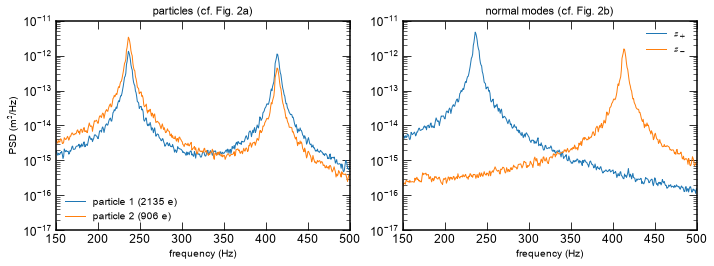

In [6]:
gain0, simulated0, predicted0, s0 = results[0]
A_modes = np.linalg.solve(vectors, s0)
energy = mode_masses[:, None] * ω2[:, None] * np.var(A_modes, axis=1)[:, None] * vectors.T**2  # [k, i]
fractions = energy / energy.sum(axis=0)
print(f'thermal equilibrium, from the simulation: E1,+/E1 = {fractions[0, 0]:.3f}, E2,+/E2 = {fractions[0, 1]:.3f}'
      f' (normal-mode prediction {fraction_1_plus:.3f}, {1 - fraction_1_plus:.3f}; paper 0.72 with the labels exchanged)')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
fs = 1 / Δt
for i, label in enumerate(('particle 1 (2135 e)', 'particle 2 (906 e)')):
    f, S = welch(s0[i], fs=fs, nperseg=2**16)
    axes[0].semilogy(f, S, label=label)
for k, label in enumerate((r'$z_+$', r'$z_-$')):
    f, S = welch(A_modes[k], fs=fs, nperseg=2**16)
    axes[1].semilogy(f, S, label=label)
for ax in axes:
    ax.set_xlim(150, 500)
    ax.set_ylim(1e-17, 1e-11)
    ax.set_xlabel('frequency (Hz)')
    ax.legend(frameon=False)
axes[0].set_ylabel(r'PSD (m$^2$/Hz)')
axes[0].set_title('particles (cf. Fig. 2a)', fontsize=11)
axes[1].set_title('normal modes (cf. Fig. 2b)', fontsize=11)
fig.tight_layout()
plt.show()

simulation against Lyapunov: largest relative deviation 5.5% over 5 gains × 2 modes


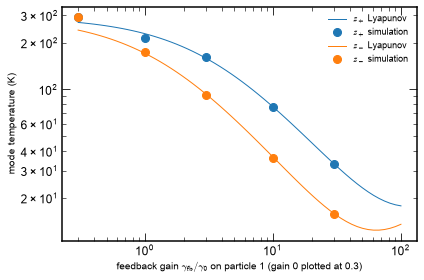

In [7]:
gains = np.array([r[0] for r in results])
simulated = np.array([r[1] for r in results])
fine = np.geomspace(0.3, 100, 60)
predicted_fine = np.array([lyapunov_prediction(γ0, g * γ0)[0] for g in fine])
fig, ax = plt.subplots(figsize=(6, 4))
for k, (label, colour) in enumerate(((r'$z_+$', 'C0'), (r'$z_-$', 'C1'))):
    ax.loglog(fine, predicted_fine[:, k], color=colour, label=f'{label} Lyapunov')
    ax.loglog(np.maximum(gains, 0.3), simulated[:, k], 'o', color=colour, label=f'{label} simulation')
ax.set_xlabel(r'feedback gain $\gamma_\mathrm{fb}/\gamma_0$ on particle 1 (gain 0 plotted at 0.3)')
ax.set_ylabel('mode temperature (K)')
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()
relative = simulated[:, :] / np.array([r[2] for r in results]) - 1
print(f'simulation against Lyapunov: largest relative deviation {np.max(np.abs(relative)):.1%} over {len(gains)} gains × 2 modes')

The weight of each mode in particle 1, $e_{k1}^2/\sum_i e_{ki}^2$, sets how strongly cold damping
of particle 1 reaches it: 0.28 for $z_+$ and 0.72 for $z_-$, so $z_-$ cools faster. At large gain
the motion of particle 1 is frozen and the modes reorganise (particle 2 alone in its trap, plus the
over-damped particle 1), which is why the $z_-$ temperature turns up again above $\gamma_\mathrm{fb} \approx 60\gamma_0$; the paper's Eqs. (20)-(21)
apply feedback to one normal mode through a band-pass filter, which this cold damping does not do.

## 4. The detection-noise-limited temperature (Eq. 22)

At 3.2 × 10⁻⁷ mbar the gas damping is $\gamma_0 \approx 10^{-3}$ s⁻¹, too slow to simulate here.
The paper's Eq. (22), $T_\pm = T_0\gamma_0/(\gamma_0 + \gamma_\mathrm{fb}) +
\tfrac12 m\omega_\pm^2\gamma_\mathrm{fb}^2 S_{nn}/[k_B(\gamma_0 + \gamma_\mathrm{fb})]$, is minimised at
$\gamma_\mathrm{fb} \approx \sqrt{2k_BT_0\gamma_0/(m\omega^2S_{nn})}$, giving
$T_\mathrm{min} \approx \sqrt{2T_0\gamma_0m\omega^2S_{nn}/k_B}$.

In [8]:
γ0_low = axial_trap(nominal['beads'][0], 0.0).Γz * (3.2e-7 / 1.3e-2)  # damping ∝ pressure
S_nn = 3e-15
for k, name in enumerate(('z+', 'z-')):
    ω = np.sqrt(ω2[k])
    γ_fb = np.geomspace(1e-3, 1e3, 4001)
    T = T0 * γ0_low / (γ0_low + γ_fb) + 0.5 * m * ω**2 * γ_fb**2 * S_nn / (kB * (γ0_low + γ_fb))
    print(f'{name}: γ0 = {γ0_low:.2e} s⁻¹, minimum of Eq. (22) T = {T.min()*1e3:.0f} mK at γfb = {γ_fb[np.argmin(T)]:.2f} s⁻¹')
print('paper: measured T+ = 200 ± 10 mK, T- = 190 ± 40 mK, "approximately twice as high as the expected temperatures"')
print(f'\ncomputation time {time.time() - T_START:.1f} s')

z+: γ0 = 6.84e-04 s⁻¹, minimum of Eq. (22) T = 104 mK at γfb = 3.85 s⁻¹
z-: γ0 = 6.84e-04 s⁻¹, minimum of Eq. (22) T = 182 mK at γfb = 2.21 s⁻¹
paper: measured T+ = 200 ± 10 mK, T- = 190 ± 40 mK, "approximately twice as high as the expected temperatures"

computation time 51.7 s


## Summary

**Agreements**

- With the paper's charges and separation, levisim's Coulomb stiffness blocks give normal modes at
  237.2 and 414.1 Hz and mode shapes $|r|$ = 1.594 and 0.628; the paper's
  $r_-$ = −1.60 ± 0.03 and $r_+$ = 0.61 ± 0.04 are these values with the particle labels exchanged,
  and its energy fraction 0.72 ± 0.03 matches 0.718.
- A `MultiTrap` of two traps holding the `PaulTrap` (the paper's electrode coefficients, endcap
  voltage from the separation, 48.7 V, inside the stated 20-50 V) and coupled by `Coulomb`
  reproduces the normal-mode frequencies to round-off.
- In the time domain the full rf force of the `PaulTrap` gives the same axial motion as its secular
  frequencies, and radial frequencies equal to the coupled pseudopotential modes plus the Floquet
  correction (Sec. 3).
- The two-particle time-domain simulation thermalises both normal modes to the bath temperature,
  recovers the energy fractions, and follows the exact Lyapunov prediction of sympathetic cooling
  by cold damping of particle 1 within the statistical scatter of the records.
- Eq. (22) with the stated pressure and imprecision noise, and levisim's gas damping, gives
  minimum temperatures of 104 mK ($z_+$) and 182 mK ($z_-$), against the measured 200 ± 10 and
  190 ± 40 mK: $z_+$ ends about twice as hot as this estimate, as the paper reports for its own
  expectation, and $z_-$ is within the measurement's uncertainty.

**Discrepancies and limits**

- The quoted $r_\pm$ use the opposite particle labelling to the quoted charges (or the reciprocal
  definition of $r$); the paper's own Eq. (12) with $Q_1$ = 2135 e gives levisim's values.
- The measured radii differ by 1.5 %, which changes $r_\pm$ by up to 7 %; the paper's comparison
  (and the main numbers here) assume equal masses.
- The measured temperatures are not reproduced from first principles: the feedback in the
  experiment is a band-passed, delayed position signal with detection noise and extra heating
  (the paper suggests electrode voltage noise), none of which is modelled here; cold damping is
  an idealisation.
- The rf voltage and frequency of this measurement are not stated (only typical ranges), so the
  radial frequencies are illustrative; they do not enter the compared numbers. The 40 s thermal
  records use the `PaulTrap`'s secular frequencies, not its rf force (too slow at this length; the rf
  force is checked against them in Sec. 3). `MultiTrap`'s quantum Langevin bath is not suitable for
  thermal spectra at this ultrastrong coupling (Sec. 2).